### Langkah 4: Melatih dan Membandingkan 5 Model Machine Learning

Notebook ini membandingkan 5 model Machine Learning:
1. Logistic Regression
2. Random Forest (Standard)
3. Balanced Random Forest (class_weight="balanced")
4. XGBoost
5. SVM (Support Vector Machine)

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve)

possible_paths = ["train_test_data.npz", os.path.join("data", "train_test_data.npz"), os.path.join("..", "data", "train_test_data.npz")]
DATA_PATH = next((p for p in possible_paths if os.path.exists(p)), None)
data = np.load(DATA_PATH, allow_pickle=True)
X_train, X_test = data["X_train"], data["X_test"]
y_train, y_test = data["y_train"], data["y_test"]
feature_names = data["feature_names"]
print(f"✓ Data berhasil dimuat: {DATA_PATH}")
print(f"✓ X_train: {X_train.shape}, X_test: {X_test.shape}")

✓ Data berhasil dimuat: data\train_test_data.npz
✓ X_train: (800, 48), X_test: (200, 48)


### 2. Inisialisasi 5 Model Machine Learning

In [2]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest (Standard)": RandomForestClassifier(n_estimators=100, random_state=42),
    "Balanced Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42, eval_metric="logloss"),
    "SVM": CalibratedClassifierCV(SVC(kernel="rbf", random_state=42), cv=3)
}

for idx, m in enumerate(models.keys(), 1):
    print(f"{idx}. {m}")
print(f"Total: {len(models)} model siap dilatih!")

1. Logistic Regression
2. Random Forest (Standard)
3. Balanced Random Forest
4. XGBoost
5. SVM
Total: 5 model siap dilatih!


### 3. Training & Tabel Perbandingan 5 Model

In [3]:
results = []
trained_models = {}
y_prob_dict = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    y_prob_dict[name] = y_prob
    
    results.append({
        "Model": name,
        "ROC-AUC (%)": round(roc_auc_score(y_test, y_prob) * 100, 2),
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Recall Bad (%) [Pencegah Macet]": round(recall_score(y_test, y_pred, pos_label=0) * 100, 2),
        "Recall Good (%)": round(recall_score(y_test, y_pred, pos_label=1) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, y_pred) * 100, 2)
    })

df_results = pd.DataFrame(results).sort_values(by="ROC-AUC (%)", ascending=False).reset_index(drop=True)
print("=== TABEL PERBANDINGAN 5 MODEL (DIURUTKAN BERDASARKAN ROC-AUC) ===")
df_results

=== TABEL PERBANDINGAN 5 MODEL (DIURUTKAN BERDASARKAN ROC-AUC) ===


,Model,ROC-AUC (%),Accuracy (%),Recall Bad (%) [Pencegah Macet],Recall Good (%),F1-Score (%)
0,Random Forest (Standard),77.60,73.5,40.00,87.86,82.27
1,Balanced Random Forest,77.33,69.0,58.33,73.57,76.87
2,SVM,76.94,75.0,38.33,90.71,83.55
3,Logistic Regression,75.92,72.0,46.67,82.86,80.56
4,XGBoost,75.55,72.5,41.67,85.71,81.36


### 4. Visualisasi Kurva ROC 5 Model

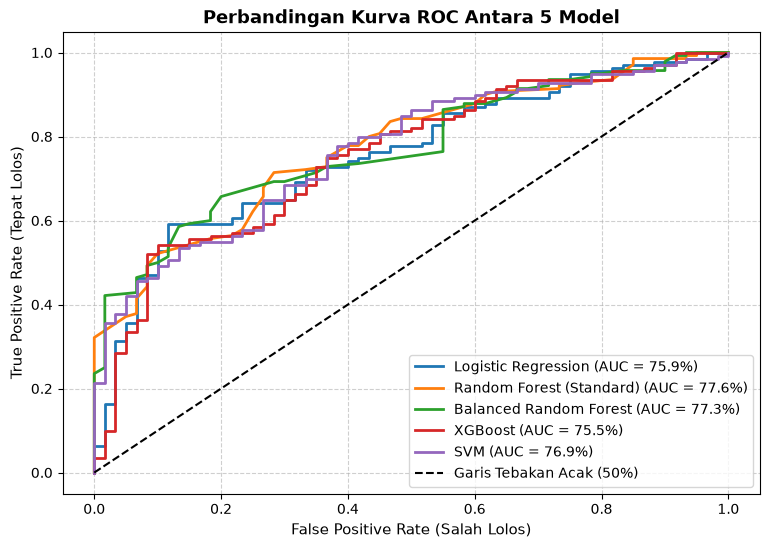

In [5]:
plt.figure(figsize=(9, 6))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
for (name, y_prob), col in zip(y_prob_dict.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc*100:.1f}%)", linewidth=2, color=col)

plt.plot([0, 1], [0, 1], "k--", label="Garis Tebakan Acak (50%)")
plt.xlabel("False Positive Rate (Salah Lolos)", fontsize=11)
plt.ylabel("True Positive Rate (Tepat Lolos)", fontsize=11)
plt.title("Perbandingan Kurva ROC Antara 5 Model", fontsize=13, fontweight="bold")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

### 5. Contoh Skor Kelayakan (0 - 100%) untuk 5 Nasabah Uji

In [6]:
sample_df = pd.DataFrame({
    "Status Asli": ["Layak (Good)" if val == 1 else "Tidak Layak (Bad)" for val in y_test[:5]]
})
for name, y_prob in y_prob_dict.items():
    sample_df[f"{name} (%)"] = np.round(y_prob[:5] * 100, 1)
print("Contoh Skor Kelayakan Kredit (0 - 100%) untuk 5 Nasabah Uji:")
sample_df

Contoh Skor Kelayakan Kredit (0 - 100%) untuk 5 Nasabah Uji:


,Status Asli,Logistic Regression (%),Random Forest (Standard) (%),Balanced Random Forest (%),XGBoost (%),SVM (%)
0,Layak (Good),74.7,76.0,64.0,71.199997,74.6
1,Layak (Good),9.1,32.0,25.0,40.500000,20.2
2,Layak (Good),44.8,53.0,57.0,63.900002,47.6
3,Layak (Good),87.1,83.0,82.0,89.900002,73.8
4,Tidak Layak (Bad),40.8,61.0,50.0,56.000000,46.4
